### Effect of mean response correction, subset selection

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import gseapy as gp
import random
from scipy.stats import pearsonr, spearmanr, energy_distance
from sklearn.metrics.pairwise import cosine_similarity

In [2]:
effects = [pd.read_csv('/nas/project1/PAGE_PJH/02.processed/replogle_k562_gwps_min10cells_effectsize.csv.gz'), 
           pd.read_csv('/nas/project1/PAGE_PJH/02.processed/replogle_k562_essential_min10cells_effectsize.csv.gz'), 
           pd.read_csv('/nas/project1/PAGE_PJH/02.processed/replogle_rpe1_min10cells_effectsize.csv.gz'), 
           pd.read_csv('/nas/project1/PAGE_PJH/02.processed/southard_rpe1_filtered_effectsize.csv.gz'),
           pd.read_csv('/nas/project1/PAGE_PJH/02.processed/nadig_hepg2_min10cells_effectsize.csv.gz'),
           pd.read_csv('/nas/project1/PAGE_PJH/02.processed/nadig_jurkat_min10cells_effectsize.csv.gz'),
           ]

noncentered_effects = [
    pd.read_csv('/nas/project1/PAGE_PJH/02.processed/replogle_k562_gwps_min10cells_noncentered_effectsize.csv.gz'), 
    pd.read_csv('/nas/project1/PAGE_PJH/02.processed/replogle_k562_essential_min10cells_noncentered_effectsize.csv.gz'), 
    pd.read_csv('/nas/project1/PAGE_PJH/02.processed/replogle_rpe1_min10cells_noncentered_effectsize.csv.gz'), 
    pd.read_csv('/nas/project1/PAGE_PJH/02.processed/southard_rpe1_filtered_noncentered_effectsize.csv.gz'),
    pd.read_csv('/nas/project1/PAGE_PJH/02.processed/nadig_hepg2_min10cells_noncentered_effectsize.csv.gz'),
    pd.read_csv('/nas/project1/PAGE_PJH/02.processed/nadig_jurkat_min10cells_noncentered_effectsize.csv.gz'),
]

decorators = ['replogle_k562_gwps', 'replogle_k562_essential', 'replogle_rpe1', 'southard_rpe1', 'nadig_hepg2', 'nadig_jurkat']
intersection_genes = np.load('/nas/project1/PAGE_PJH/01.rawdata/00.data_gene_symbols/intersection.npy')

Perturbation space, mean response correction

0
replogle_k562_gwps
0.004237768767597497 0.004732832189519675 0.005482604693109744 0.004572741768241338
1
replogle_k562_essential
0.02525235529962383 0.029191015587087144 0.007195098757415692 0.004551286096461852
2
replogle_rpe1
0.13711290694314135 0.16078338396044844 -0.008852059243905263 -0.009314159173891105
3
southard_rpe1
0.07730834444741533 0.07791245218349997 -0.00024360661510592317 -0.00012501773699027214
4
nadig_hepg2
0.0458998279856061 0.0508044343787975 0.003783346726600201 0.0019116056670563574
5
nadig_jurkat
0.03800163513759805 0.04244823090832104 0.00044035418884393485 -0.001006269436250133


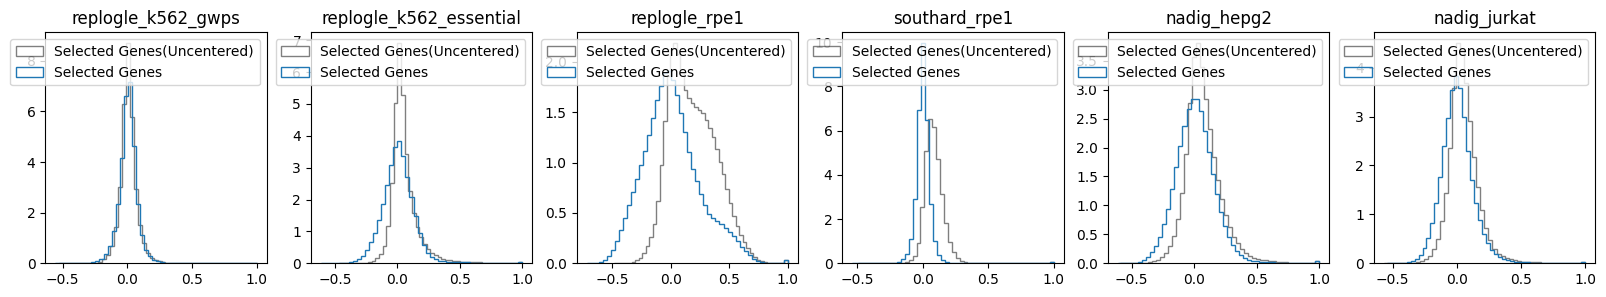

In [3]:
from scipy.stats import kstest
import seaborn as sns

fig, ax = plt.subplots(1, 6, figsize=(20, 3))
for j, eff in enumerate(effects):
    print(j)
    try:
        effect = eff.set_index('guide')
        noncentered_effect = noncentered_effects[j].set_index('guide')
        
    except:
        effect = eff.set_index('Unnamed: 0')
        noncentered_effect = noncentered_effects[j].set_index('Unnamed: 0')

    selected_ones = list(set(effect.index).intersection(intersection_genes))
    all_elements = np.triu(cosine_similarity(effect.values)).flatten()
    selected_elements = np.triu(cosine_similarity(effect.loc[selected_ones].values)).flatten()
    all_elements = all_elements[all_elements!=0]
    all_elements = all_elements[all_elements!=1]
    selected_elements = selected_elements[selected_elements!=0]
    selected_elements = selected_elements[selected_elements!=1]

    all_noncentered_elements = np.triu(cosine_similarity(noncentered_effect.values)).flatten()
    selected_noncentered_elements = np.triu(cosine_similarity(noncentered_effect.loc[selected_ones].values)).flatten()
    all_noncentered_elements = all_noncentered_elements[all_noncentered_elements!=0]
    all_noncentered_elements = all_noncentered_elements[all_noncentered_elements!=1]
    selected_noncentered_elements = selected_noncentered_elements[selected_noncentered_elements!=0]
    selected_noncentered_elements = selected_noncentered_elements[selected_noncentered_elements!=1]

    #sns.boxplot(x=0, y=all_noncentered_elements, color='black', label='All Genes(Uncentered)', ax=ax[j])
    #sns.boxplot(x=1, y=selected_noncentered_elements, color='tab:blue', label='Selected Genes(Uncentered)', ax=ax[j])
    #sns.boxplot(x=2, y=all_elements, color='black', label='All Genes(Centered)', ax=ax[j])
    #sns.boxplot(x=3, y=selected_elements, color='tab:blue', label='Selected Genes(Centered)', ax=ax[j])

    #ax[j].hist(all_noncentered_elements, bins=50, alpha=0.5, color='black', histtype=u'step', density=True, label='All Genes(Uncentered)')
    ax[j].hist(selected_noncentered_elements, bins=50, alpha=0.5, color='black', histtype=u'step', density=True, label='Selected Genes(Uncentered)')
    #ax[j].hist(all_elements, bins=50, alpha=0.5, color='grey', density=True, label='All Genes')
    ax[j].hist(selected_elements, bins=50, color='tab:blue', histtype=u'step', density=True, label='Selected Genes')
    ax[j].set_title(decorators[j])
    ax[j].legend()

    print(decorators[j])
    print(np.median(all_noncentered_elements), np.median(selected_noncentered_elements), np.median(all_elements), np.median(selected_elements))
plt.savefig('./figure_out/Fig2D_1.pdf')

Perturbation space, subset selection

0
replogle_k562_gwps
0.004237768767597497 0.004732832189519675 0.005482604693109744 0.004572741768241338
1
replogle_k562_essential
0.02525235529962383 0.029191015587087144 0.007195098757415692 0.004551286096461852
2
replogle_rpe1
0.13711290694314135 0.16078338396044844 -0.008852059243905263 -0.009314159173891105
3
southard_rpe1
0.07730834444741533 0.07791245218349997 -0.00024360661510592317 -0.00012501773699027214
4
nadig_hepg2
0.0458998279856061 0.0508044343787975 0.003783346726600201 0.0019116056670563574
5
nadig_jurkat
0.03800163513759805 0.04244823090832104 0.00044035418884393485 -0.001006269436250133


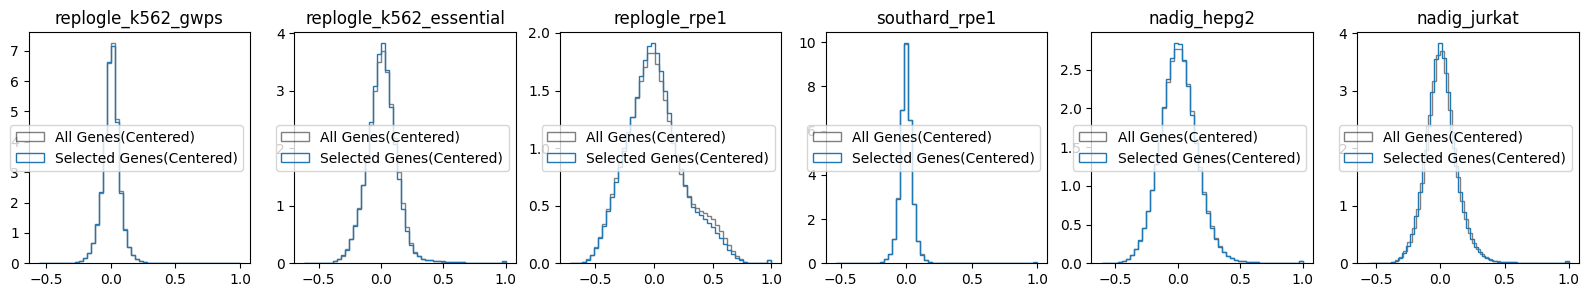

In [ ]:
from scipy.stats import kstest
import seaborn as sns

fig, ax = plt.subplots(1, 6, figsize=(20,3))
for j, eff in enumerate(effects):
    print(j)
    try:
        effect = eff.set_index('guide')
        noncentered_effect = noncentered_effects[j].set_index('guide')
        
    except:
        effect = eff.set_index('Unnamed: 0')
        noncentered_effect = noncentered_effects[j].set_index('Unnamed: 0')

    selected_ones = list(set(effect.index).intersection(intersection_genes))
    all_elements = np.triu(cosine_similarity(effect.values)).flatten()
    selected_elements = np.triu(cosine_similarity(effect.loc[selected_ones].values)).flatten()
    all_elements = all_elements[all_elements!=0]
    all_elements = all_elements[all_elements!=1]
    selected_elements = selected_elements[selected_elements!=0]
    selected_elements = selected_elements[selected_elements!=1]

    all_noncentered_elements = np.triu(cosine_similarity(noncentered_effect.values)).flatten()
    selected_noncentered_elements = np.triu(cosine_similarity(noncentered_effect.loc[selected_ones].values)).flatten()
    all_noncentered_elements = all_noncentered_elements[all_noncentered_elements!=0]
    all_noncentered_elements = all_noncentered_elements[all_noncentered_elements!=1]
    selected_noncentered_elements = selected_noncentered_elements[selected_noncentered_elements!=0]
    selected_noncentered_elements = selected_noncentered_elements[selected_noncentered_elements!=1]

    #sns.boxplot(x=0, y=all_noncentered_elements, color='black', label='All Genes(Uncentered)', ax=ax[j])
    #sns.boxplot(x=1, y=selected_noncentered_elements, color='tab:blue', label='Selected Genes(Uncentered)', ax=ax[j])
    #sns.boxplot(x=2, y=all_elements, color='black', label='All Genes(Centered)', ax=ax[j])
    #sns.boxplot(x=3, y=selected_elements, color='tab:blue', label='Selected Genes(Centered)', ax=ax[j])

    ax[j].hist(all_elements, bins=50, alpha=0.5, color='black', histtype=u'step', density=True, label='All Genes(Centered)')
    ax[j].hist(selected_elements, bins=50, color='tab:blue', histtype=u'step', density=True, label='Selected Genes(Centered)')
    ax[j].set_title(decorators[j])
    ax[j].legend()

    print(decorators[j])
    print(np.median(all_noncentered_elements), np.median(selected_noncentered_elements), np.median(all_elements), np.median(selected_elements))
plt.savefig('./figure_out/FigS1_1.pdf')

mRNA spcae, mean response correction

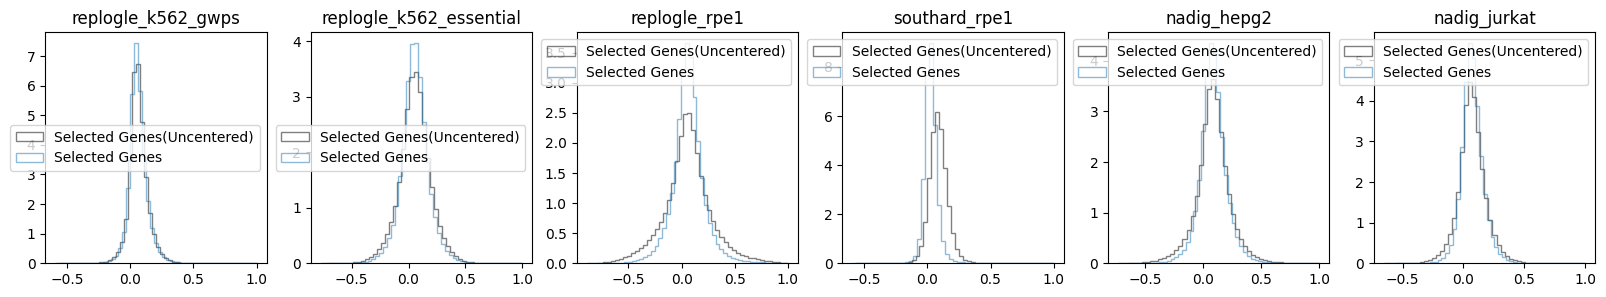

In [5]:
fig, ax = plt.subplots(1, 6, figsize=(20, 3))
for j, eff in enumerate(effects):
    try:
        effect = eff.set_index('guide').T
        noncentered_effect = noncentered_effects[j].set_index('guide').T
        
    except:
        effect = eff.set_index('Unnamed: 0').T
        noncentered_effect = noncentered_effects[j].set_index('Unnamed: 0').T
    selected_ones = list(set(effect.index).intersection(intersection_genes))
    all_elements = np.triu(cosine_similarity(effect.values)).flatten()
    selected_elements = np.triu(cosine_similarity(effect.loc[selected_ones].values)).flatten()
    all_elements = all_elements[all_elements!=0]
    all_elements = all_elements[all_elements!=1]
    selected_elements = selected_elements[selected_elements!=0]
    selected_elements = selected_elements[selected_elements!=1]

    all_noncentered_elements = np.triu(cosine_similarity(noncentered_effect.values)).flatten()
    selected_noncentered_elements = np.triu(cosine_similarity(noncentered_effect.loc[selected_ones].values)).flatten()
    all_noncentered_elements = all_noncentered_elements[all_noncentered_elements!=0]
    all_noncentered_elements = all_noncentered_elements[all_noncentered_elements!=1]
    selected_noncentered_elements = selected_noncentered_elements[selected_noncentered_elements!=0]
    selected_noncentered_elements = selected_noncentered_elements[selected_noncentered_elements!=1]

    #ax[j].hist(all_noncentered_elements, bins=50, alpha=0.5, color='black', histtype=u'step', density=True, label='All Genes(Uncentered)')
    ax[j].hist(selected_noncentered_elements, bins=50, alpha=0.5, color='black', histtype=u'step', density=True, label='Selected Genes(Uncentered)')
    #ax[j].hist(all_elements, bins=50, alpha=0.5, color='grey', density=True, label='All Genes')
    ax[j].hist(selected_elements, bins=50, alpha=0.5, color='tab:blue', histtype=u'step', density=True, label='Selected Genes')
    ax[j].set_title(decorators[j])
    ax[j].legend()
plt.savefig('./figure_out/Fig2D_2.pdf')

mRNA space, subset selection

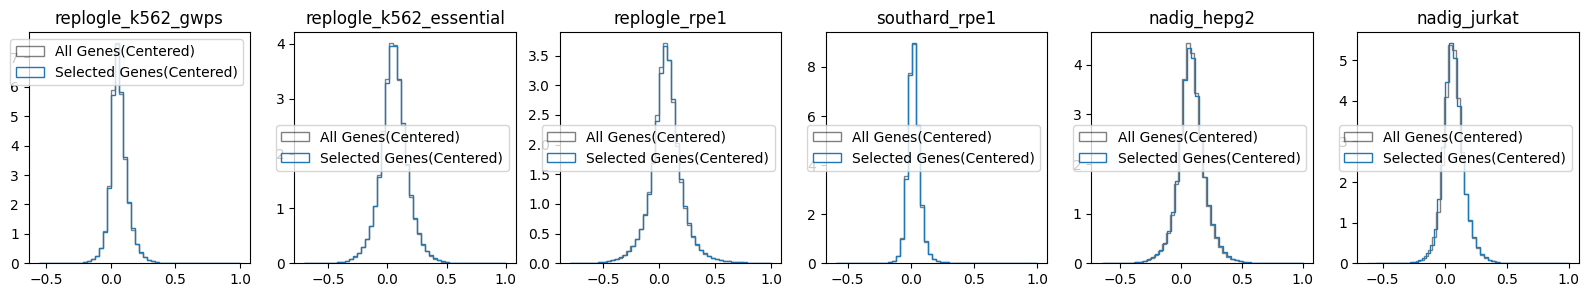

In [ ]:
fig, ax = plt.subplots(1, 6, figsize=(20, 3))
for j, eff in enumerate(effects):
    try:
        effect = eff.set_index('guide').T
        noncentered_effect = noncentered_effects[j].set_index('guide').T
        
    except:
        effect = eff.set_index('Unnamed: 0').T
        noncentered_effect = noncentered_effects[j].set_index('Unnamed: 0').T
    selected_ones = list(set(effect.index).intersection(intersection_genes))
    all_elements = np.triu(cosine_similarity(effect.values)).flatten()
    selected_elements = np.triu(cosine_similarity(effect.loc[selected_ones].values)).flatten()
    all_elements = all_elements[all_elements!=0]
    all_elements = all_elements[all_elements!=1]
    selected_elements = selected_elements[selected_elements!=0]
    selected_elements = selected_elements[selected_elements!=1]

    all_noncentered_elements = np.triu(cosine_similarity(noncentered_effect.values)).flatten()
    selected_noncentered_elements = np.triu(cosine_similarity(noncentered_effect.loc[selected_ones].values)).flatten()
    all_noncentered_elements = all_noncentered_elements[all_noncentered_elements!=0]
    all_noncentered_elements = all_noncentered_elements[all_noncentered_elements!=1]
    selected_noncentered_elements = selected_noncentered_elements[selected_noncentered_elements!=0]
    selected_noncentered_elements = selected_noncentered_elements[selected_noncentered_elements!=1]

    ax[j].hist(all_elements, bins=50, alpha=0.5, color='black', histtype=u'step', density=True, label='All Genes(Centered)')
    ax[j].hist(selected_elements, bins=50, color='tab:blue', histtype=u'step', density=True, label='Selected Genes(Centered)')
    ax[j].set_title(decorators[j])
    ax[j].legend()
plt.savefig('./figure_out/FigS1_2.pdf')